In [1]:
import os
import sys
import re
import subprocess
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

PROJECT_DIR = "/root/autodl-tmp/train"
DATA_DIR = "/root/autodl-tmp/medical_data/hemorrhage_vs_tumor"

DATASET_NAME = "HemorrhageVsTumor"
NUM_CLASSES = 2

EPOCHS = 30
BATCH_SIZE = 16
N_FEATURE = BATCH_SIZE
GPU = 0

# StableNet开启
EPOCHP = 0

SEEDS = [1, 3, 7, 21, 42]

os.chdir(PROJECT_DIR)

In [31]:
all_seed_results = []
all_seed_outputs = {}

for run_index, seed in enumerate(SEEDS, start=1):
    log_base = (
        f"/root/autodl-tmp/train/"
        f"results_5seeds/seed_{seed}"
    )

    cmd = [
        sys.executable,
        "-u",
        "main_stablenet.py",

        "-data", DATA_DIR,
        "--dataset", DATASET_NAME,
        "--classes_num", str(NUM_CLASSES),

        "--gpu", str(GPU),
        "--batch-size", str(BATCH_SIZE),
        "--n_feature", str(N_FEATURE),
        "--workers", "4",

        "--epochs", str(EPOCHS),
        "--epochp", str(EPOCHP),
        "--seed", str(seed),

        "--lr", "0.001",
        "--wd", "0.0001",
        "--cos", "1",

        "--lrbl", "1",
        "--lambdap", "70",
        "--epochb", "20",

        "--log_base", log_base,
    ]

    print()
    print("=" * 65)
    print(f"第 {run_index}/{len(SEEDS)} 次实验，随机种子：{seed}")
    print("=" * 65)

    process = subprocess.Popen(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    lines = []
    evaluation_index = 0

    for line in process.stdout:
        lines.append(line)
        stripped = line.strip()

        if "* Acc@1" in line:
            epoch = evaluation_index // 2 + 1
            phase = (
                "Validation"
                if evaluation_index % 2 == 0
                else "Test"
            )

            print(
                f"Seed {seed:2d} | "
                f"Epoch {epoch:02d} | "
                f"{phase:10s} | {stripped}"
            )

            evaluation_index += 1

    process.wait()
    raw_output = "".join(lines)
    all_seed_outputs[seed] = raw_output

    if process.returncode != 0:
        print(f"\nSeed {seed} 训练失败")

        for line in lines[-60:]:
            print(line, end="")

        continue

    # 同时兼容Acc@2和Acc@5
    matches = re.findall(
        r"\*\s+Acc@1\s+([-\d.]+)"
        r"\s+Acc@(?:2|5)\s+([-\d.]+)",
        raw_output
    )

    epoch_results = []

    for i in range(0, len(matches), 2):
        if i + 1 >= len(matches):
            break

        val_accuracy = float(matches[i][0])
        test_accuracy = float(matches[i + 1][0])

        epoch_results.append({
            "epoch": i // 2 + 1,
            "val_accuracy": val_accuracy,
            "test_accuracy": test_accuracy,
        })

    if not epoch_results:
        print("没有解析到准确率")
        continue

    # 只能根据验证集选择最佳epoch
    best = max(
        epoch_results,
        key=lambda item: item["val_accuracy"]
    )

    model_path = (
        Path(log_base) /
        DATASET_NAME /
        "model_best.pth.tar"
    )

    all_seed_results.append({
        "Seed": seed,
        "Best Epoch": best["epoch"],
        "Validation Accuracy": best["val_accuracy"],
        "Test Accuracy": best["test_accuracy"],
        "Model Path": str(model_path),
        "Model Exists": model_path.is_file(),
    })

    print(
        f"\nSeed {seed} 完成："
        f"最佳epoch={best['epoch']}，"
        f"验证={best['val_accuracy']:.2f}%，"
        f"测试={best['test_accuracy']:.2f}%"
    )


第 1/5 次实验，随机种子：1
Seed  1 | Epoch 01 | Validation | * Acc@1 76.667 Acc@5 100.000
Seed  1 | Epoch 01 | Test       | * Acc@1 83.333 Acc@5 100.000
Seed  1 | Epoch 02 | Validation | * Acc@1 93.333 Acc@5 100.000
Seed  1 | Epoch 02 | Test       | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 03 | Validation | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 03 | Test       | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 04 | Validation | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 04 | Test       | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 05 | Validation | * Acc@1 100.000 Acc@5 100.000
Seed  1 | Epoch 05 | Test       | * Acc@1 100.000 Acc@5 100.000


KeyboardInterrupt: 

In [32]:
seed_df = pd.DataFrame(all_seed_results)

display(
    seed_df.style.format({
        "Validation Accuracy": "{:.2f}%",
        "Test Accuracy": "{:.2f}%"
    })
)

In [33]:
val_mean = seed_df["Validation Accuracy"].mean()
val_std = seed_df["Validation Accuracy"].std(ddof=1)

test_mean = seed_df["Test Accuracy"].mean()
test_std = seed_df["Test Accuracy"].std(ddof=1)

summary_df = pd.DataFrame([
    {
        "Metric": "Validation Accuracy",
        "Mean": val_mean,
        "Standard Deviation": val_std,
        "Report": f"{val_mean:.2f}% ± {val_std:.2f}%"
    },
    {
        "Metric": "Test Accuracy",
        "Mean": test_mean,
        "Standard Deviation": test_std,
        "Report": f"{test_mean:.2f}% ± {test_std:.2f}%"
    }
])

display(summary_df)


KeyError: 'Validation Accuracy'

In [14]:
print("Grad-CAM可视化")

Grad-CAM可视化


In [15]:
from pathlib import Path
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt
import torch

In [17]:
BEST_MODEL = (
    "/root/autodl-tmp/train/"
    "results_5seeds/seed_42/"
    "HemorrhageVsTumor/"
    "model_best.pth.tar"
)

In [37]:
import os
import sys
import torch
import torch.nn as nn

from types import SimpleNamespace

os.chdir("/root/autodl-tmp/train")

if "/root/autodl-tmp/train" not in sys.path:
    sys.path.insert(0, "/root/autodl-tmp/train")

import models

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

model_args = SimpleNamespace(
    n_feature=N_FEATURE,
    feature_dim=512,
    n_levels=1
)

model = models.resnet18_with_table(
    pretrained=False,
    args=model_args
)

# 改成当前二分类输出层
model.fc1 = nn.Linear(
    model.fc1.in_features,
    NUM_CLASSES
)

checkpoint = torch.load(
    BEST_MODEL,
    map_location=device,
    weights_only=False
)

state_dict = checkpoint["state_dict"]

# 兼容由DataParallel保存的module.前缀
if any(key.startswith("module.") for key in state_dict):
    state_dict = {
        key.removeprefix("module."): value
        for key, value in state_dict.items()
    }

model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

print("模型加载成功")
print("checkpoint epoch：", checkpoint.get("epoch"))
print("模型路径：", BEST_MODEL)

模型加载成功
checkpoint epoch： 2
模型路径： /root/autodl-tmp/train/results_5seeds/seed_42/HemorrhageVsTumor/model_best.pth.tar


In [38]:
from torchvision import transforms

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("✓ test_transform 已定义")

✓ test_transform 已定义


In [39]:
required_names = [
    "model",
    "device",
    "test_transform",
    "class_names",
    "occlusion_sensitivity",
    "show_occlusion_result",
]

all_ready = True

for name in required_names:
    exists = name in globals()
    status = "✓ 已定义" if exists else "✗ 未定义"

    print(f"{name:24s}: {status}")

    if not exists:
        all_ready = False

print()
print(
    "可以开始遮挡实验"
    if all_ready
    else "请先运行缺失变量对应的单元格"
)

model                   : ✓ 已定义
device                  : ✓ 已定义
test_transform          : ✓ 已定义
class_names             : ✓ 已定义
occlusion_sensitivity   : ✓ 已定义
show_occlusion_result   : ✓ 已定义

可以开始遮挡实验


In [40]:
from pathlib import Path
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F


def occlusion_sensitivity(
    image_path,
    patch_size=32,
    stride=16,
    target_class=None,
    batch_size=64
):
    image_path = Path(image_path)

    original = Image.open(image_path).convert("RGB")
    resized = original.resize((224, 224))

    input_tensor = (
        test_transform(original)
        .unsqueeze(0)
        .to(device)
    )

    model.eval()

    # 原始预测
    with torch.no_grad():
        logits, _ = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)

    predicted_class = int(
        probabilities.argmax(dim=1).item()
    )

    if target_class is None:
        target_class = predicted_class

    baseline_probability = float(
        probabilities[0, target_class].item()
    )

    _, _, height, width = input_tensor.shape

    occluded_images = []
    positions = []

    for y in range(0, height - patch_size + 1, stride):
        for x in range(0, width - patch_size + 1, stride):
            occluded = input_tensor.clone()

            # 标准化后的0相当于ImageNet均值颜色
            occluded[
                :,
                :,
                y:y + patch_size,
                x:x + patch_size
            ] = 0.0

            occluded_images.append(occluded)
            positions.append((x, y))

    occluded_batch = torch.cat(
        occluded_images,
        dim=0
    )

    occluded_probabilities = []

    # 分批推理，避免显存占用过大
    with torch.no_grad():
        for start in range(
            0,
            len(occluded_batch),
            batch_size
        ):
            batch = occluded_batch[
                start:start + batch_size
            ]

            logits, _ = model(batch)
            probability = torch.softmax(
                logits,
                dim=1
            )[:, target_class]

            occluded_probabilities.extend(
                probability.cpu().numpy()
            )

    score_map = np.zeros(
        (height, width),
        dtype=np.float32
    )

    count_map = np.zeros(
        (height, width),
        dtype=np.float32
    )

    for (x, y), occluded_probability in zip(
        positions,
        occluded_probabilities
    ):
        # 正数越大，表示遮挡这里后置信度下降越明显
        probability_drop = (
            baseline_probability -
            float(occluded_probability)
        )

        score_map[
            y:y + patch_size,
            x:x + patch_size
        ] += probability_drop

        count_map[
            y:y + patch_size,
            x:x + patch_size
        ] += 1

    score_map = score_map / np.maximum(
        count_map,
        1
    )

    return {
        "image": np.asarray(resized).astype(
            np.float32
        ) / 255.0,
        "score_map": score_map,
        "predicted_class": predicted_class,
        "target_class": target_class,
        "baseline_probability": baseline_probability,
        "image_path": image_path,
    }

In [41]:
def show_occlusion_result(result):
    image = result["image"]
    score_map = result["score_map"]

    # 只显示导致目标类别置信度下降的区域
    positive_scores = np.maximum(
        score_map,
        0
    )

    if positive_scores.max() > 0:
        normalized_scores = (
            positive_scores /
            positive_scores.max()
        )
    else:
        normalized_scores = positive_scores

    color_map = plt.get_cmap("jet")(
        normalized_scores
    )[..., :3]

    overlay = np.clip(
        0.55 * image +
        0.45 * color_map,
        0,
        1
    )

    predicted_name = class_names[
        result["predicted_class"]
    ]

    baseline = (
        result["baseline_probability"] * 100
    )

    figure, axes = plt.subplots(
        1,
        3,
        figsize=(14, 4)
    )

    axes[0].imshow(image)
    axes[0].set_title("Original")

    heatmap_plot = axes[1].imshow(
        score_map,
        cmap="jet"
    )

    axes[1].set_title(
        "Occlusion sensitivity\n"
        "Red = confidence drops more"
    )

    plt.colorbar(
        heatmap_plot,
        ax=axes[1],
        fraction=0.046
    )

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"Prediction: {predicted_name}\n"
        f"Original confidence: {baseline:.2f}%"
    )

    for axis in axes:
        axis.axis("off")

    plt.suptitle(
        result["image_path"].name
    )

    plt.tight_layout()
    plt.show()

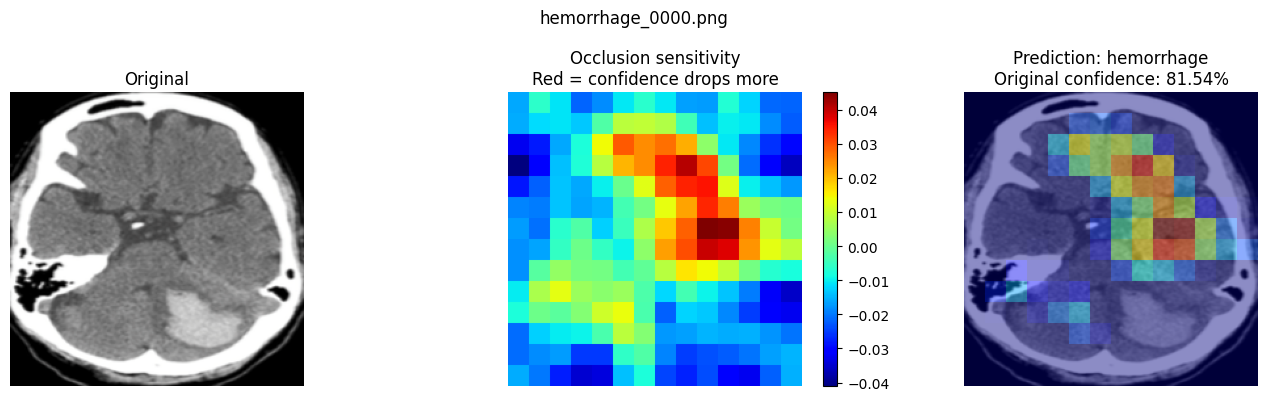

In [42]:
hemorrhage_image = next(
    (
        Path(DATA_DIR) /
        "test" /
        "hemorrhage"
    ).glob("*")
)

hemorrhage_result = occlusion_sensitivity(
    hemorrhage_image,
    patch_size=32,
    stride=16
)

show_occlusion_result(
    hemorrhage_result
)

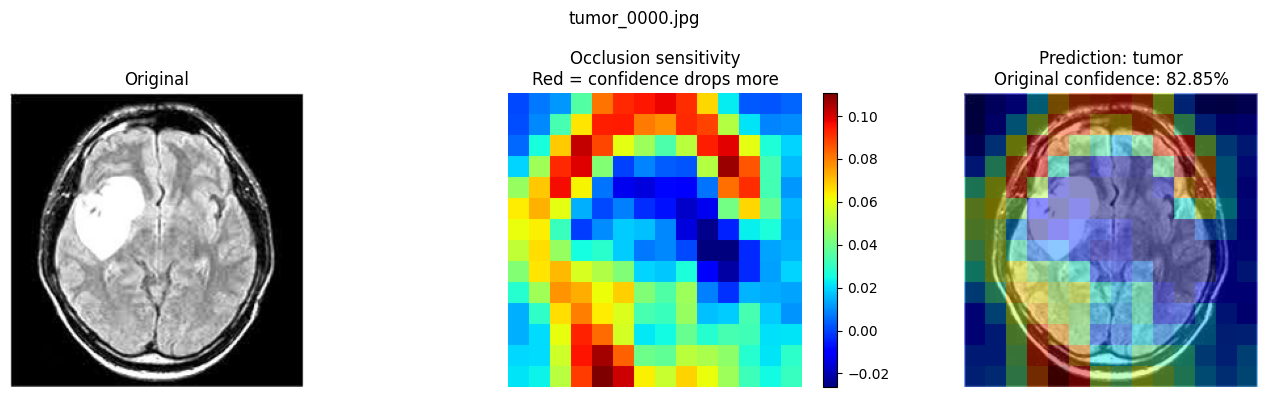

In [43]:
tumor_image = next(
    (
        Path(DATA_DIR) /
        "test" /
        "tumor"
    ).glob("*")
)

tumor_result = occlusion_sensitivity(
    tumor_image,
    patch_size=32,
    stride=16
)

show_occlusion_result(
    tumor_result
)

In [1]:
from pathlib import Path
from PIL import Image

import numpy as np
import shutil

source_dataset = Path(
    "/root/autodl-tmp/medical_data/"
    "hemorrhage_vs_tumor"
)

mask_root = Path(
    "/root/autodl-tmp/brain_masks"
)

output_dataset = Path(
    "/root/autodl-tmp/medical_data/"
    "hemorrhage_vs_tumor_brain_only"
)

if output_dataset.exists():
    shutil.rmtree(output_dataset)

mask_directories = {
    "hemorrhage": mask_root / "ct" / "masks",
    "tumor": mask_root / "mri" / "masks",
}

success = 0
missing = []
errors = []

In [2]:
def apply_brain_mask(
    image_path,
    mask_path,
    output_path,
    padding_ratio=0.03
):
    image = Image.open(image_path).convert("L")
    mask = Image.open(mask_path).convert("L")

    if mask.size != image.size:
        mask = mask.resize(
            image.size,
            Image.Resampling.NEAREST
        )

    image_array = np.asarray(
        image,
        dtype=np.uint8
    )

    mask_array = (
        np.asarray(mask, dtype=np.uint8) > 127
    )

    if mask_array.sum() == 0:
        raise ValueError("掩膜为空")

    # 去除脑区外像素
    brain_array = image_array.copy()
    brain_array[~mask_array] = 0

    # 依据脑掩膜确定裁剪范围
    ys, xs = np.where(mask_array)

    y_min, y_max = int(ys.min()), int(ys.max())
    x_min, x_max = int(xs.min()), int(xs.max())

    height = y_max - y_min + 1
    width = x_max - x_min + 1

    padding_y = int(height * padding_ratio)
    padding_x = int(width * padding_ratio)

    y_min = max(0, y_min - padding_y)
    y_max = min(
        brain_array.shape[0] - 1,
        y_max + padding_y
    )

    x_min = max(0, x_min - padding_x)
    x_max = min(
        brain_array.shape[1] - 1,
        x_max + padding_x
    )

    cropped = brain_array[
        y_min:y_max + 1,
        x_min:x_max + 1
    ]

    result = Image.fromarray(cropped).resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    # 统一保存为三通道PNG
    result = result.convert("RGB")

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    result.save(output_path, format="PNG")

In [3]:
for stage in ("train", "val", "test"):
    for class_name in ("hemorrhage", "tumor"):
        source_directory = (
            source_dataset /
            stage /
            class_name
        )

        for dataset_image in source_directory.glob("*"):
            if not dataset_image.is_file():
                continue

            # 如果当前数据集使用的是软链接，
            # resolve()可以得到原始文件名
            original_image = dataset_image.resolve()
            original_stem = original_image.stem

            mask_path = (
                mask_directories[class_name] /
                f"{original_stem}.png"
            )

            output_path = (
                output_dataset /
                stage /
                class_name /
                f"{dataset_image.stem}.png"
            )

            if not mask_path.is_file():
                missing.append({
                    "dataset_image": str(dataset_image),
                    "original_image": str(original_image),
                    "expected_mask": str(mask_path),
                })
                continue

            try:
                apply_brain_mask(
                    image_path=original_image,
                    mask_path=mask_path,
                    output_path=output_path,
                )
                success += 1

            except Exception as error:
                errors.append({
                    "image": str(original_image),
                    "mask": str(mask_path),
                    "error": repr(error),
                })

print("成功生成：", success)
print("找不到掩膜：", len(missing))
print("处理失败：", len(errors))

if missing:
    print("\n前5个缺失掩膜：")

    for item in missing[:5]:
        print(item)

if errors:
    print("\n前5个处理错误：")

    for item in errors[:5]:
        print(item)

成功生成： 200
找不到掩膜： 0
处理失败： 0


In [4]:
from torchvision.datasets import ImageFolder

for stage in ("train", "val", "test"):
    dataset = ImageFolder(
        output_dataset / stage
    )

    print(
        stage,
        "数量 =", len(dataset),
        "类别 =", dataset.class_to_idx
    )

train 数量 = 140 类别 = {'hemorrhage': 0, 'tumor': 1}
val 数量 = 30 类别 = {'hemorrhage': 0, 'tumor': 1}
test 数量 = 30 类别 = {'hemorrhage': 0, 'tumor': 1}


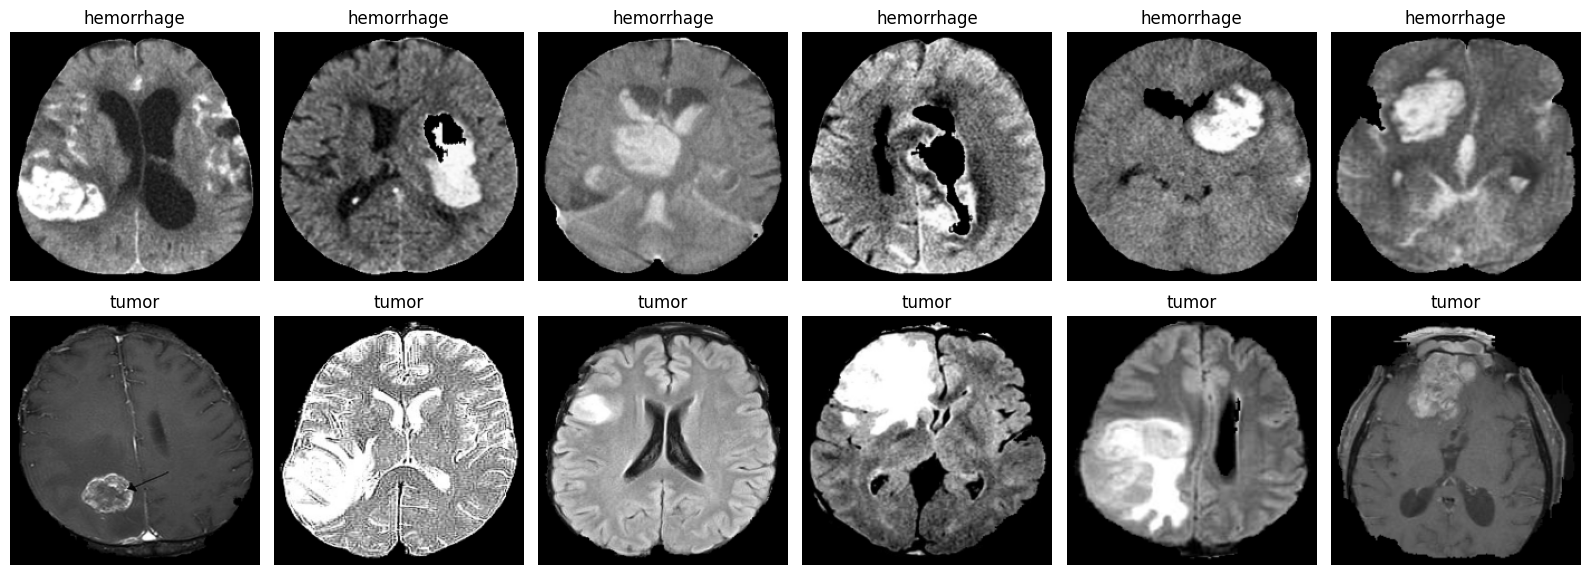

In [5]:
import random
import matplotlib.pyplot as plt

figure, axes = plt.subplots(
    2,
    6,
    figsize=(16, 6)
)

for row, class_name in enumerate(
    ("hemorrhage", "tumor")
):
    files = list(
        (
            output_dataset /
            "train" /
            class_name
        ).glob("*.png")
    )

    selected = random.sample(
        files,
        min(6, len(files))
    )

    for column, path in enumerate(selected):
        image = Image.open(path)

        axes[row, column].imshow(
            image,
            cmap="gray"
        )
        axes[row, column].set_title(class_name)
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

In [1]:
import os
import sys
import re
import subprocess
import torch
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import transforms
from torchvision.datasets import ImageFolder
from IPython.display import display, HTML

DATA_DIR = (
    "/root/autodl-tmp/medical_data/"
    "hemorrhage_vs_tumor_brain_only"
)

DATASET_NAME = "HemorrhageVsTumorBrainOnly_ResNet18"
# DATASET_NAME = "HemorrhageVsTumorBrainOnly_StableNet"


EPOCHS = 30
BATCH_SIZE = 16
N_FEATURE = BATCH_SIZE

# 普通ResNet18
EPOCHP = 100

# # StableNet
# EPOCHP = 0



In [2]:
for stage in ("train", "val", "test"):
    stage_dir = Path(DATA_DIR) / stage

    dataset = ImageFolder(stage_dir)

    print(
        f"{stage:5s} | "
        f"数量={len(dataset):3d} | "
        f"类别={dataset.class_to_idx}"
    )

train | 数量=140 | 类别={'hemorrhage': 0, 'tumor': 1}
val   | 数量= 30 | 类别={'hemorrhage': 0, 'tumor': 1}
test  | 数量= 30 | 类别={'hemorrhage': 0, 'tumor': 1}


In [7]:
import os
import sys
import re
import subprocess
import torch
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import transforms
from torchvision.datasets import ImageFolder
from IPython.display import display, HTML


PROJECT_DIR = "/root/autodl-tmp/train"

DATA_DIR = (
    "/root/autodl-tmp/medical_data/"
    "hemorrhage_vs_tumor_brain_only"
)

# # 当前先训练普通ResNet18
# DATASET_NAME = (
#     "HemorrhageVsTumorBrainOnly_ResNet18"
# )

# 当前先训练普通ResNet18
DATASET_NAME = (
    "HemorrhageVsTumorBrainOnly_StableNet"
)

NUM_CLASSES = 2
EPOCHS = 30
BATCH_SIZE = 16
N_FEATURE = BATCH_SIZE
GPU = 0

# 100：关闭StableNet重加权
EPOCHP = 0

LR = 0.001
WEIGHT_DECAY = 0.0001

LRBL = 1.0
LAMBDAP = 70.0
EPOCHB = 20

os.chdir(PROJECT_DIR)

print("=" * 60)
print(" Brain-only 医学图像分类实验")
print("=" * 60)
print(f"模型             : ResNet18")
print(f"数据集           : {DATASET_NAME}")
print(f"数据目录         : {DATA_DIR}")
print(f"类别数           : {NUM_CLASSES}")
print(f"Epochs           : {EPOCHS}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Feature buffer   : {N_FEATURE}")
print(f"StableNet        : {'ON' if EPOCHP < EPOCHS else 'OFF'}")
print(f"GPU              : {torch.cuda.get_device_name(GPU)}")
print("=" * 60)

 Brain-only 医学图像分类实验
模型             : ResNet18
数据集           : HemorrhageVsTumorBrainOnly_StableNet
数据目录         : /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_brain_only
类别数           : 2
Epochs           : 30
Batch size       : 16
Feature buffer   : 16
StableNet        : ON
GPU              : NVIDIA RTX 6000D


In [8]:
cmd = [
    sys.executable,
    "-u",
    "main_stablenet.py",

    "-data", DATA_DIR,
    "--dataset", DATASET_NAME,
    "--classes_num", str(NUM_CLASSES),

    "--gpu", str(GPU),
    "--batch-size", str(BATCH_SIZE),
    "--n_feature", str(N_FEATURE),
    "--workers", "4",

    "--epochs", str(EPOCHS),
    "--epochp", str(EPOCHP),

    "--lr", str(LR),
    "--wd", str(WEIGHT_DECAY),
    "--cos", "1",

    "--lrbl", str(LRBL),
    "--lambdap", str(LAMBDAP),
    "--epochb", str(EPOCHB),
]

print("开始训练\n")
print("运行命令：")
print(" ".join(cmd))
print()

process = subprocess.Popen(
    cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

all_lines = []
evaluation_index = 0

for line in process.stdout:
    all_lines.append(line)
    stripped = line.strip()

    if "Epoch:" in line:
        match = re.search(
            r"\[(\d+)/(\d+)\]",
            line
        )

        if match:
            batch_index = int(match.group(1))

            if batch_index == 0 or batch_index % 20 == 0:
                print(stripped)

    elif "* Acc@1" in line:
        epoch = evaluation_index // 2 + 1

        phase = (
            "Validation"
            if evaluation_index % 2 == 0
            else "Test"
        )

        print(
            f">>> Epoch {epoch:02d} "
            f"{phase:10s} | {stripped}"
        )

        evaluation_index += 1

process.wait()
raw_output = "".join(all_lines)

print()
print("=" * 60)
print("训练结束")
print("return code =", process.returncode)
print("=" * 60)

if process.returncode != 0:
    print("\n===== 最后80行输出 =====")

    for line in all_lines[-80:]:
        print(line, end="")

开始训练

运行命令：
/root/miniconda3/bin/python -u main_stablenet.py -data /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_brain_only --dataset HemorrhageVsTumorBrainOnly_StableNet --classes_num 2 --gpu 0 --batch-size 16 --n_feature 16 --workers 4 --epochs 30 --epochp 0 --lr 0.001 --wd 0.0001 --cos 1 --lrbl 1.0 --lambdap 70.0 --epochb 20

Epoch: [0][0/8]	Time  0.872 ( 0.872)	Data  0.127 ( 0.127)	Loss 6.6077e-01 (6.6077e-01)	Acc@1  68.75 ( 68.75)	Acc@5 100.00 (100.00)
>>> Epoch 01 Validation | * Acc@1 96.667 Acc@5 100.000
>>> Epoch 01 Test       | * Acc@1 100.000 Acc@5 100.000
Epoch: [1][0/8]	Time  0.217 ( 0.217)	Data  0.143 ( 0.143)	Loss 5.5207e-01 (5.5207e-01)	Acc@1  68.75 ( 68.75)	Acc@5 100.00 (100.00)
>>> Epoch 02 Validation | * Acc@1 93.333 Acc@5 100.000
>>> Epoch 02 Test       | * Acc@1 96.667 Acc@5 100.000
Epoch: [2][0/8]	Time  0.201 ( 0.201)	Data  0.127 ( 0.127)	Loss 3.4762e-01 (3.4762e-01)	Acc@1 100.00 (100.00)	Acc@5 100.00 (100.00)
>>> Epoch 03 Validation | * Acc@1 90.000 Acc@5 100.

In [9]:
matches = re.findall(
    r"\*\s+Acc@1\s+([-\d.]+)"
    r"\s+Acc@(?:2|5)\s+([-\d.]+)",
    raw_output
)

results = []

for index in range(0, len(matches), 2):
    if index + 1 >= len(matches):
        break

    epoch = index // 2 + 1

    validation_accuracy = float(
        matches[index][0]
    )

    test_accuracy = float(
        matches[index + 1][0]
    )

    results.append({
        "Epoch": epoch,
        "Validation Accuracy": validation_accuracy,
        "Test Accuracy": test_accuracy,
    })

df = pd.DataFrame(results)

if len(df):
    display(
        df.style
        .format({
            "Validation Accuracy": "{:.2f}%",
            "Test Accuracy": "{:.2f}%"
        })
        .highlight_max(
            subset=["Validation Accuracy"],
            color="#b7e4c7"
        )
    )
else:
    print("没有解析到结果")

,Epoch,Validation Accuracy,Test Accuracy
0,1,96.67%,100.00%
1,2,93.33%,96.67%
2,3,90.00%,96.67%
3,4,96.67%,100.00%
4,5,100.00%,100.00%
5,6,100.00%,100.00%
6,7,100.00%,100.00%
7,8,100.00%,100.00%
8,9,100.00%,100.00%
9,10,100.00%,100.00%


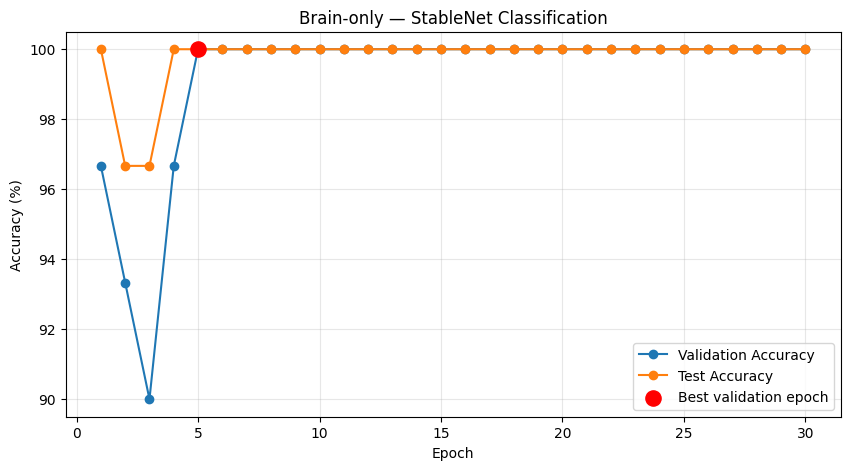

模型： StableNet
结果已保存： /root/autodl-tmp/train/results/HemorrhageVsTumorBrainOnly_StableNet/metrics.csv


In [13]:
if len(df) > 1:
    plt.figure(figsize=(10, 5))

    plt.plot(
        df["Epoch"],
        df["Validation Accuracy"],
        marker="o",
        label="Validation Accuracy"
    )

    plt.plot(
        df["Epoch"],
        df["Test Accuracy"],
        marker="o",
        label="Test Accuracy"
    )

    best_index = (
        df["Validation Accuracy"].idxmax()
    )
    best = df.loc[best_index]

    plt.scatter(
        best["Epoch"],
        best["Validation Accuracy"],
        color="red",
        s=120,
        zorder=5,
        label="Best validation epoch"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    model_name = (
        "StableNet"
        if EPOCHP < EPOCHS
        else "ResNet18"
    )
    
    plt.title(
        f"Brain-only — {model_name} Classification"
    )
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

    result_file = Path(
    f"/root/autodl-tmp/train/"
    f"results/{DATASET_NAME}/metrics.csv"
)

result_file.parent.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(result_file, index=False)

print("模型：", model_name)
print("结果已保存：", result_file)

In [11]:
print("=" * 60)
print("当前数据目录：", DATA_DIR)
print("当前实验名称：", DATASET_NAME)
print("EPOCHP：", EPOCHP)
print(
    "实际模型：",
    "StableNet" if EPOCHP < EPOCHS else "ResNet18"
)
print("=" * 60)

当前数据目录： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_brain_only
当前实验名称： HemorrhageVsTumorBrainOnly_StableNet
EPOCHP： 0
实际模型： StableNet


In [35]:
MODEL_NAME = "ResNet18"

BEST_MODEL = (
    "/root/autodl-tmp/train/results/"
    "HemorrhageVsTumorBrainOnly_ResNet18/"
    "model_best.pth.tar"
)

In [36]:
DATA_DIR = (
    "/root/autodl-tmp/medical_data/"
    "hemorrhage_vs_tumor_brain_only"
)

In [37]:
import os
import sys
import torch
import torch.nn as nn

from pathlib import Path
from types import SimpleNamespace
from torchvision.datasets import ImageFolder

PROJECT_DIR = "/root/autodl-tmp/train"
NUM_CLASSES = 2
N_FEATURE = 16

os.chdir(PROJECT_DIR)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import models

device = torch.device(
    "cuda:0" if torch.cuda.is_available()
    else "cpu"
)

# 自动读取正确的类别顺序
test_dataset = ImageFolder(
    Path(DATA_DIR) / "test"
)

class_names = test_dataset.classes

print("类别顺序：", class_names)
print("模型文件：", BEST_MODEL)

if not Path(BEST_MODEL).is_file():
    raise FileNotFoundError(
        f"找不到模型：{BEST_MODEL}"
    )

model_args = SimpleNamespace(
    n_feature=N_FEATURE,
    feature_dim=512,
    n_levels=1
)

model = models.resnet18_with_table(
    pretrained=False,
    args=model_args
)

model.fc1 = nn.Linear(
    model.fc1.in_features,
    NUM_CLASSES
)

checkpoint = torch.load(
    BEST_MODEL,
    map_location=device,
    weights_only=False
)

state_dict = checkpoint["state_dict"]

# 兼容DataParallel保存的module.前缀
if any(
    key.startswith("module.")
    for key in state_dict
):
    state_dict = {
        key.removeprefix("module."): value
        for key, value in state_dict.items()
    }

model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

print("=" * 55)
print("模型加载成功")
print("模型类型：", MODEL_NAME)
print("Checkpoint epoch：", checkpoint.get("epoch"))
print("类别：", class_names)
print("=" * 55)

类别顺序： ['hemorrhage', 'tumor']
模型文件： /root/autodl-tmp/train/results/HemorrhageVsTumorBrainOnly_ResNet18/model_best.pth.tar
模型加载成功
模型类型： ResNet18
Checkpoint epoch： 1
类别： ['hemorrhage', 'tumor']


In [38]:
from torchvision import transforms

test_transform = transforms.Compose([
    transforms.Grayscale(
        num_output_channels=3
    ),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("✓ test_transform 已定义")

✓ test_transform 已定义


In [39]:
if "grad_cam" in globals():
    try:
        grad_cam.close()
        print("✓ 已关闭旧Grad-CAM hook")
    except Exception:
        pass

✓ 已关闭旧Grad-CAM hook


In [40]:
import torch
import torch.nn.functional as F


class GradCAM:
    def __init__(
        self,
        model,
        target_layer
    ):
        self.model = model
        self.activations = None
        self.gradients = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self._save_activations
            )
        )

        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self._save_gradients
            )
        )

    def _save_activations(
        self,
        module,
        inputs,
        output
    ):
        self.activations = output.detach()

    def _save_gradients(
        self,
        module,
        grad_input,
        grad_output
    ):
        self.gradients = grad_output[0].detach()

    def __call__(
        self,
        input_tensor,
        target_class=None
    ):
        self.model.zero_grad(set_to_none=True)

        model_output = self.model(input_tensor)

        # 兼容StableNet返回(output, features)
        if isinstance(model_output, tuple):
            logits = model_output[0]
        else:
            logits = model_output

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        if target_class is None:
            target_class = int(
                logits.argmax(dim=1).item()
            )

        score = logits[:, target_class].sum()
        score.backward()

        if self.activations is None:
            raise RuntimeError(
                "没有获取到激活值，请检查target_layer"
            )

        if self.gradients is None:
            raise RuntimeError(
                "没有获取到梯度，请检查target_layer"
            )

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * self.activations
        ).sum(
            dim=1,
            keepdim=True
        )

        cam = torch.relu(cam)

        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0]
        cam = cam - cam.min()
        cam = cam / cam.max().clamp_min(1e-8)

        return (
            cam.detach().cpu().numpy(),
            target_class,
            probabilities[0].detach().cpu().numpy()
        )

    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()


print("✓ GradCAM类已定义")

✓ GradCAM类已定义


In [41]:
grad_cam = GradCAM(
    model=model,
    target_layer=model.layer4[-1]
)

print("✓ Grad-CAM已绑定到新模型")

✓ Grad-CAM已绑定到新模型


In [42]:
from pathlib import Path
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt


def show_gradcam(
    image_path,
    target_class=None
):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(
            f"找不到图片：{image_path}"
        )

    # 读取原图
    original = Image.open(
        image_path
    ).convert("RGB")

    resized = original.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    # 使用与测试集相同的预处理
    input_tensor = (
        test_transform(original)
        .unsqueeze(0)
        .to(device)
    )

    # 生成Grad-CAM
    heatmap, predicted_class, probabilities = (
        grad_cam(
            input_tensor,
            target_class=target_class
        )
    )

    original_array = (
        np.asarray(resized)
        .astype(np.float32) / 255.0
    )

    color_heatmap = plt.get_cmap(
        "jet"
    )(heatmap)[..., :3]

    overlay = (
        0.55 * original_array +
        0.45 * color_heatmap
    )

    overlay = np.clip(
        overlay,
        0,
        1
    )

    predicted_name = (
        class_names[predicted_class]
    )

    confidence = (
        probabilities[predicted_class] * 100
    )

    figure, axes = plt.subplots(
        1,
        3,
        figsize=(13, 4)
    )

    axes[0].imshow(original_array)
    axes[0].set_title("Brain-only Image")

    axes[1].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Grad-CAM")

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"Model: {MODEL_NAME}\n"
        f"Prediction: {predicted_name}\n"
        f"Confidence: {confidence:.2f}%"
    )

    for axis in axes:
        axis.axis("off")

    plt.suptitle(
        image_path.name,
        fontsize=13
    )

    plt.tight_layout()
    plt.show()

    return {
        "image": str(image_path),
        "predicted_class": predicted_class,
        "predicted_name": predicted_name,
        "confidence": float(confidence),
        "probabilities": probabilities,
    }


print("✓ show_gradcam函数已定义")

✓ show_gradcam函数已定义


In [43]:
required_names = [
    "model",
    "device",
    "grad_cam",
    "test_transform",
    "class_names",
    "MODEL_NAME",
    "show_gradcam",
]

for name in required_names:
    print(
        f"{name:15s}:",
        "✓ 已定义"
        if name in globals()
        else "✗ 未定义"
    )

model          : ✓ 已定义
device         : ✓ 已定义
grad_cam       : ✓ 已定义
test_transform : ✓ 已定义
class_names    : ✓ 已定义
MODEL_NAME     : ✓ 已定义
show_gradcam   : ✓ 已定义


模型： ResNet18
图片： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_brain_only/test/hemorrhage/hemorrhage_0000.png


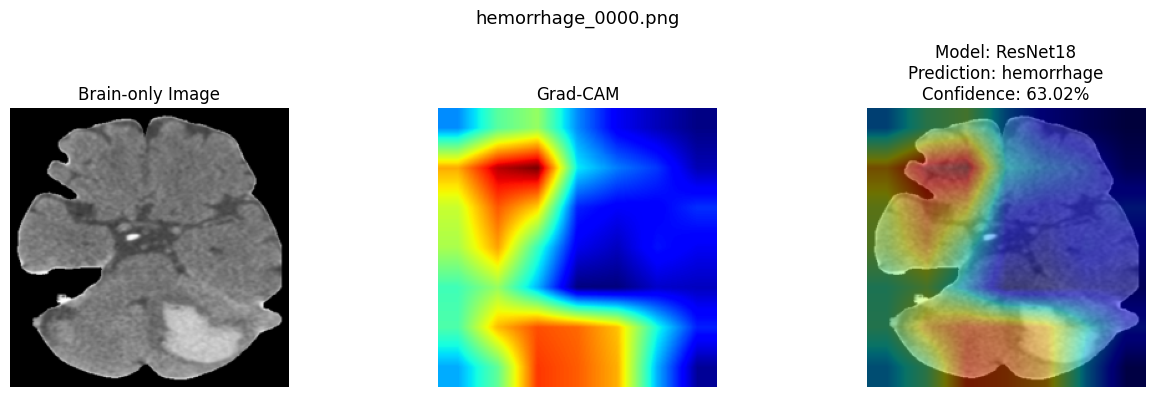

{'image': '/root/autodl-tmp/medical_data/hemorrhage_vs_tumor_brain_only/test/hemorrhage/hemorrhage_0000.png',
 'predicted_class': 0,
 'predicted_name': 'hemorrhage',
 'confidence': 63.01802444458008,
 'probabilities': array([0.63018024, 0.3698197 ], dtype=float32)}

In [44]:
hemorrhage_image = next(
    (
        Path(DATA_DIR) /
        "test" /
        "hemorrhage"
    ).glob("*")
)

print("模型：", MODEL_NAME)
print("图片：", hemorrhage_image)

show_gradcam(hemorrhage_image)

模型： ResNet18
图片： /root/autodl-tmp/medical_data/hemorrhage_vs_tumor_brain_only/test/tumor/tumor_0000.png


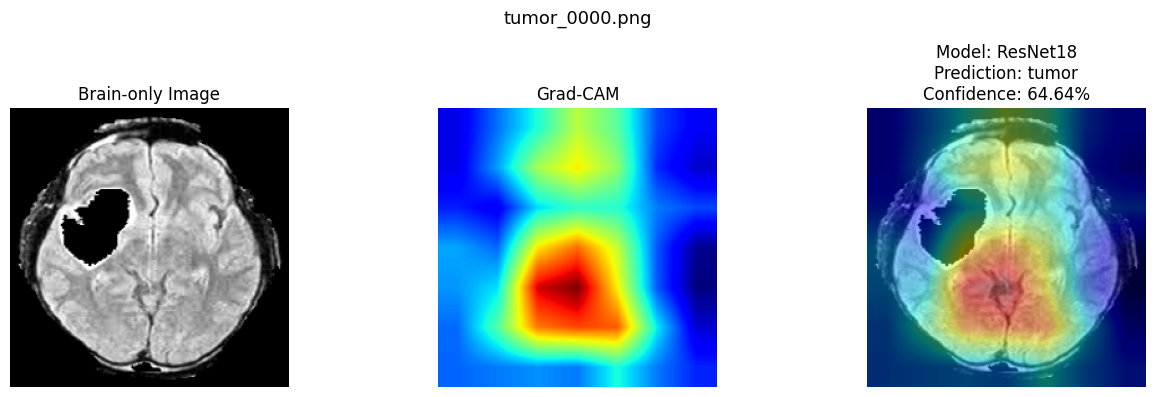

{'image': '/root/autodl-tmp/medical_data/hemorrhage_vs_tumor_brain_only/test/tumor/tumor_0000.png',
 'predicted_class': 1,
 'predicted_name': 'tumor',
 'confidence': 64.6395034790039,
 'probabilities': array([0.35360503, 0.646395  ], dtype=float32)}

In [45]:
tumor_image = next(
    (
        Path(DATA_DIR) /
        "test" /
        "tumor"
    ).glob("*")
)

print("模型：", MODEL_NAME)
print("图片：", tumor_image)

show_gradcam(tumor_image)


模型： ResNet18
真实类别： hemorrhage


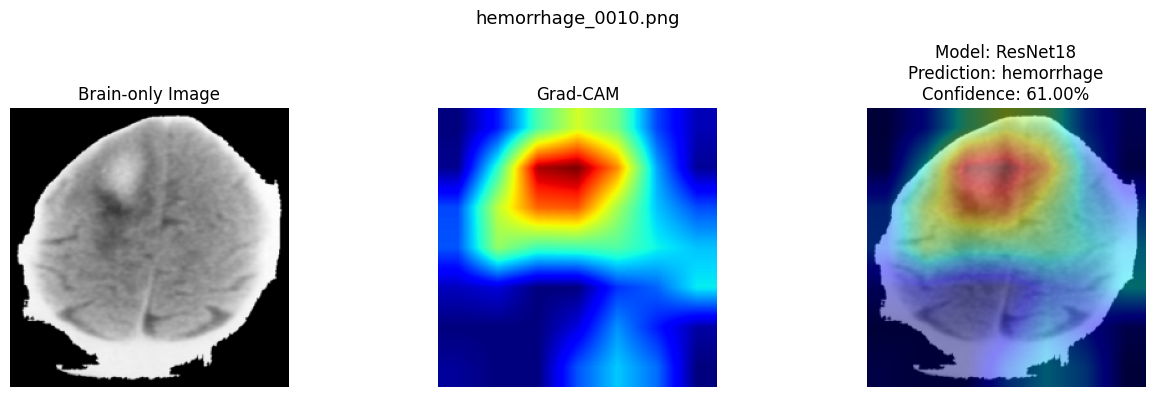

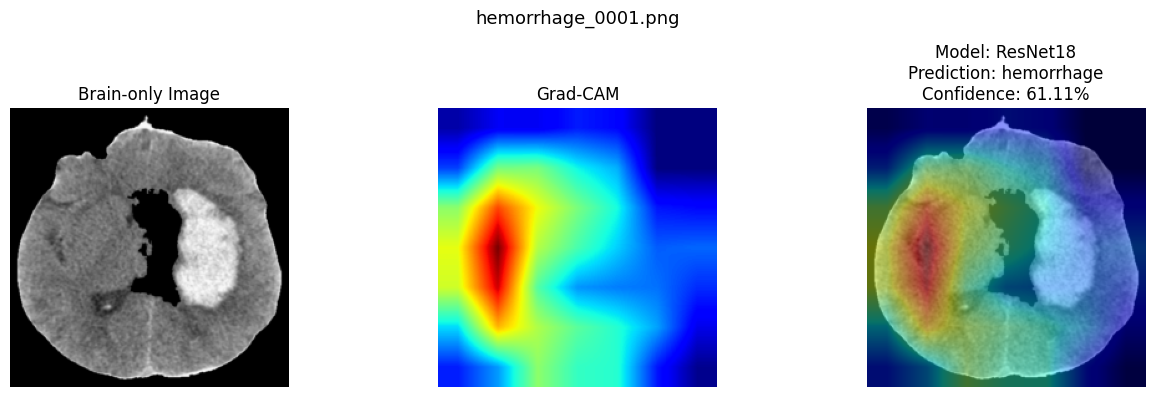

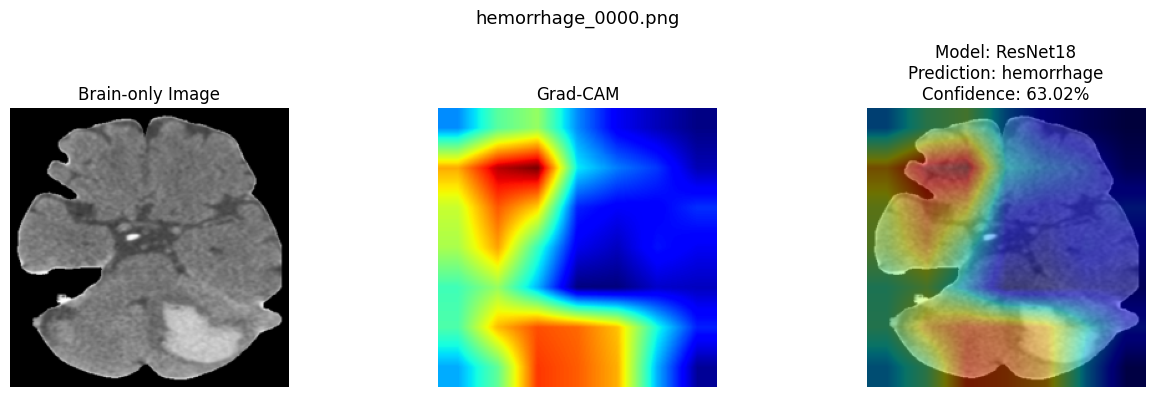

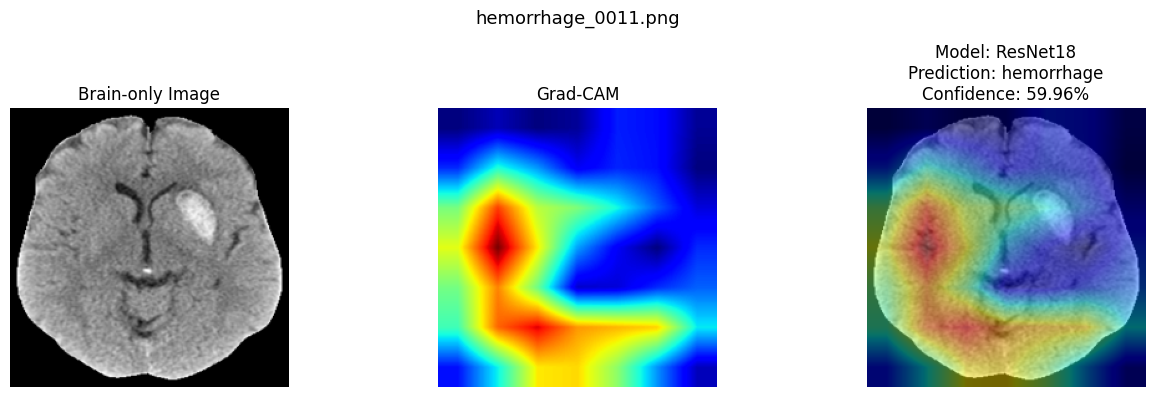

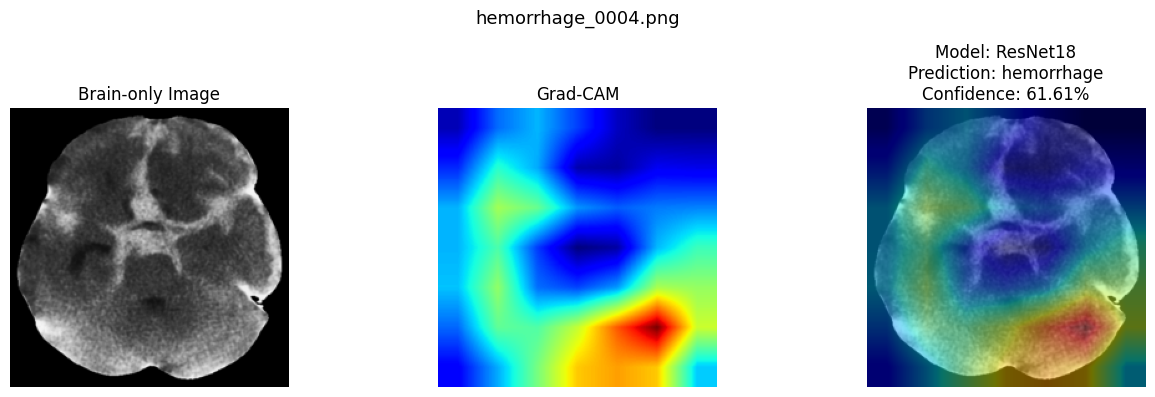


模型： ResNet18
真实类别： tumor


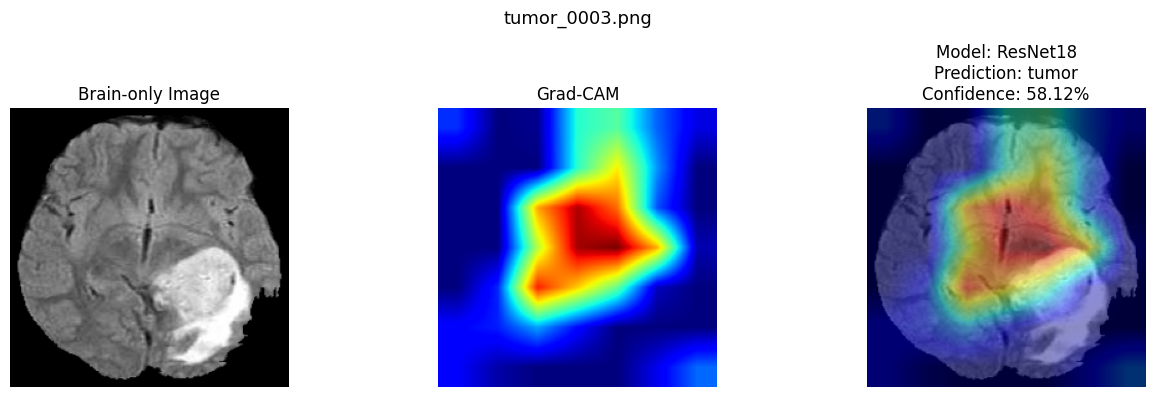

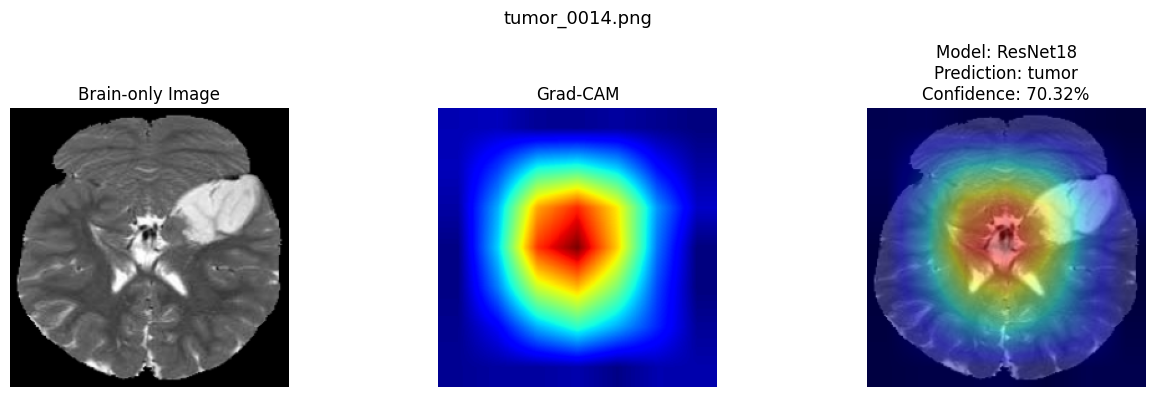

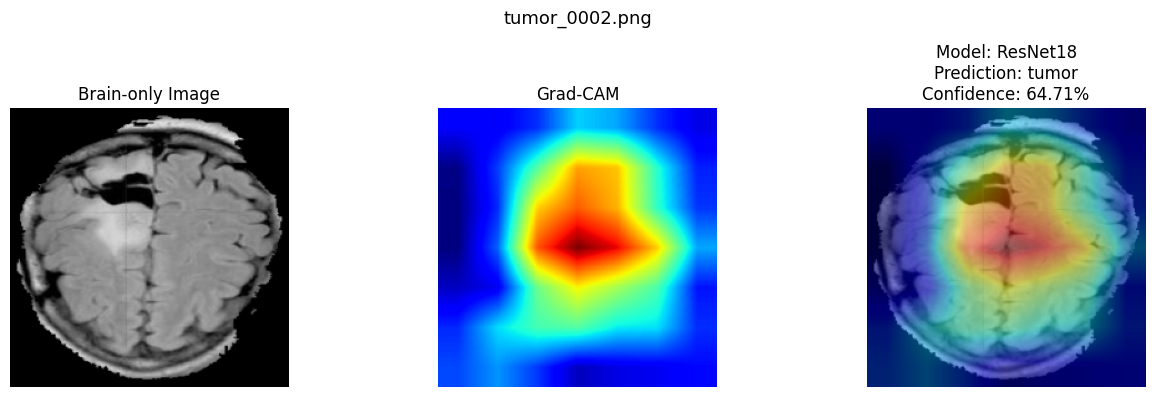

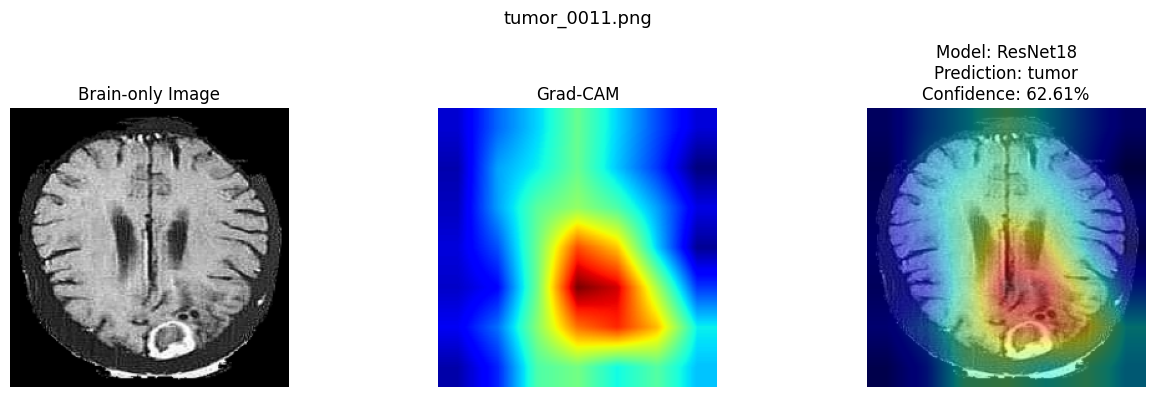

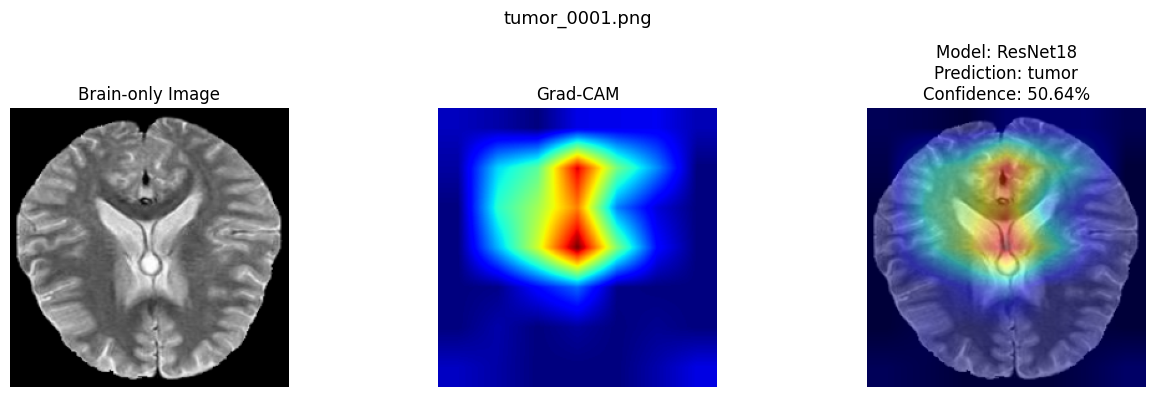

In [46]:
import random

random.seed(42)

for class_name in class_names:
    files = list(
        (
            Path(DATA_DIR) /
            "test" /
            class_name
        ).glob("*")
    )

    selected = random.sample(
        files,
        min(5, len(files))
    )

    print()
    print("=" * 60)
    print("模型：", MODEL_NAME)
    print("真实类别：", class_name)
    print("=" * 60)

    for image_path in selected:
        show_gradcam(image_path)